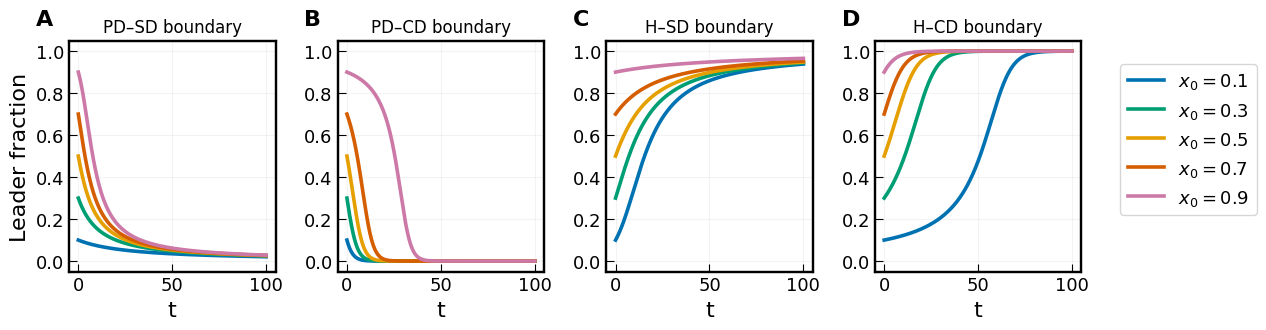

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

plt.rcParams.update({
    "font.size": 12,
    "axes.labelsize": 16,
    "xtick.labelsize": 13,
    "ytick.labelsize": 13,
    "legend.fontsize": 13,
    "axes.linewidth": 1.6,
    "lines.linewidth": 2.6,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.major.size": 6,
    "ytick.major.size": 6,
})

alpha, delta = 0.4, 0.6
x0_list = [0.1, 0.3, 0.5, 0.7, 0.9]
N0 = 1.0

# Four boundary cases
scenarios = [
    ("A", "PD–SD boundary",          0.60, 0.80),
    ("B", "PD–CD boundary",      0.20, 0.40),
    ("C", "H–SD boundary",    0.80, 0.40),
    ("D", "H–CD boundary", 0.60, 0.20),
]

# Simulate for 200 days
t0, t1, dt = 0.0, 100.0, 0.01
T = np.arange(t0, t1 + dt, dt)

colors = [
    "#0072B2",
    "#009E73",
    "#E69F00",
    "#D55E00",
    "#CC79A7",
]

def simulate(beta, gamma):
    def fL(x):
        return alpha*x + beta*(1 - x)

    def fF(x):
        return gamma*x + delta*(1 - x)

    def dNdt(N, x):
        return (((fL(x) - fF(x)) * x) + fF(x)) * N

    def dxdt(x):
        return (fL(x) - fF(x)) * x * (1 - x)

    def rk4_step(N, x, h):
        k1x = dxdt(x)
        k1N = dNdt(N, x)

        x2 = x + 0.5*h*k1x
        N2 = N + 0.5*h*k1N
        k2x = dxdt(x2)
        k2N = dNdt(N2, x2)

        x3 = x + 0.5*h*k2x
        N3 = N + 0.5*h*k2N
        k3x = dxdt(x3)
        k3N = dNdt(N3, x3)

        x4 = x + h*k3x
        N4 = N + h*k3N
        k4x = dxdt(x4)
        k4N = dNdt(N4, x4)

        x_next = x + (h/6)*(k1x + 2*k2x + 2*k3x + k4x)
        N_next = N + (h/6)*(k1N + 2*k2N + 2*k3N + k4N)

        x_next = min(1.0, max(0.0, x_next))
        N_next = max(0.0, N_next)

        return N_next, x_next

    X, N = {}, {}

    for x0 in x0_list:
        x = x0
        n = N0

        x_vals = np.empty_like(T)
        n_vals = np.empty_like(T)

        x_vals[0] = x
        n_vals[0] = n

        for i in range(1, len(T)):
            n, x = rk4_step(n, x, dt)
            x_vals[i] = x
            n_vals[i] = n

        X[x0] = x_vals
        N[x0] = n_vals

    return X, N

results = {}
for code, name, beta, gamma in scenarios:
    results[code] = simulate(beta, gamma)

def add_panel_box(ax, lw=1.6, color="black"):
    rect = Rectangle(
        (0, 0), 1, 1,
        transform=ax.transAxes,
        fill=False,
        linewidth=lw,
        edgecolor=color,
        clip_on=False
    )
    ax.add_patch(rect)

def style_axes(ax, y_label=None):
    for side in ["top", "right", "left", "bottom"]:
        ax.spines[side].set_visible(True)
        ax.spines[side].set_linewidth(1.6)

    if y_label is not None:
        ax.set_ylabel(y_label)

    ax.set_xlabel("t")
    ax.grid(True, alpha=0.15)

# Plot 1 row × 4 columns
fig, axes = plt.subplots(1, 4, figsize=(15, 3), constrained_layout=False)
fig.subplots_adjust(right=0.80, wspace=0.30)

panel_letters = ["A", "B", "C", "D"]

for col, (code, name, beta, gamma) in enumerate(scenarios):

    X, NN = results[code]

    ax = axes[col]

    for x0, c in zip(x0_list, colors):
        ax.plot(T, X[x0], label=f"$x_0={x0}$", color=c)

    style_axes(ax, y_label="Leader fraction" if col == 0 else None)

    ax.set_ylim(-0.05, 1.05)
    ax.set_title(name, fontsize=12)

    add_panel_box(ax)

    ax.annotate(
        panel_letters[col],
        xy=(-0.16, 1.05),
        xycoords="axes fraction",
        ha="left",
        va="bottom",
        fontsize=16,
        fontweight="bold",
        annotation_clip=False
    )

handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="center left",
    bbox_to_anchor=(0.82, 0.55),
    frameon=True
)

plt.show()

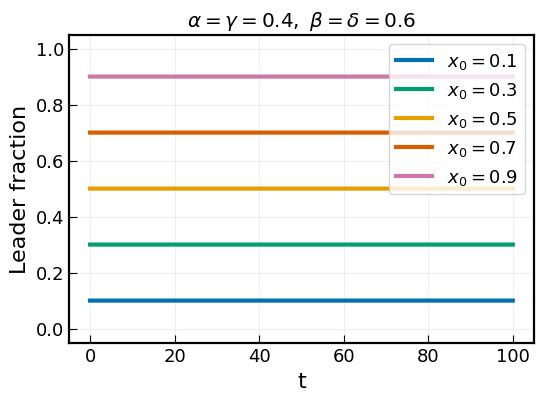

In [ ]:
beta = 0.60
gamma = 0.40

X, NN = simulate(beta, gamma)

plt.figure(figsize=(6,4))

for x0, c in zip(x0_list, colors):
    plt.plot(T, X[x0], lw=3, color=c,
             label=fr"$x_0={x0}$")

plt.xlabel("t")
plt.ylabel("Leader fraction")
plt.ylim(-0.05,1.05)
plt.legend()
plt.grid(alpha=0.2)

plt.title(r"$\alpha=\gamma=0.4,\ \beta=\delta=0.6$")
plt.show()